# Debugging example frames, my model vs Denis (3-fish recording)

One frame at a time (set `FRAME`), from the examples of `EOD_examples_3fish_better_frames.ipynb` (better list of good frames).
My model: BEM conductivities (interior 100 × water, skin 0.05 × water over 0.005 cm), sink at the tail tip, unit current, the other
two fish as bodies; patterns × −1 and scaled to max |v| = 1 when compared with the recording. Figures go to
`results/eod_ground_truth_3fish/conductivities/debug_frames/`.
The longer tests on frame 14111 (rotation, sinks, emitter as a body, conductivity scans) are kept, run, in
`EOD_debug_frames_3fish_frame14111.ipynb`.


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import eod_examples as ex                       # tank + zoom + voltages figure, recording loading
%matplotlib inline
from compute_electric_field import (multipole_sources, build_multipole_b, occupancy_field, build_A_shell, solve_potential, gammas,
                                    unflatten_to_grid)
from eod_assign import pair_voltages

FRAME = 14111
PAIR = 8                                        # electrode pair to look at (orientation cell)
OUT = 'results/eod_ground_truth_3fish/conductivities/debug_frames'
os.makedirs(OUT, exist_ok=True)
N = 150; h = 1 / (N - 1)                        # field grid
CELL_CM = (912 - 1) / (N - 1) / ex.PX_PER_CM
BEM = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=100.0, eps_interior=0.0,
           sigma_skin=1 / (0.1 / 0.005 + 1 / 100.0), eps_skin=0.0)   # skin as resistive as 0.1 cm of water, over 0.005 cm
DELTA_H = 0.005 / CELL_CM                       # skin thickness in grid cells

c = ex.emitter_usual_lengths(ex.use_better_list(ex.load_recording('3-fish')))

## The EOD

frame 14111: EOD row(s) [9410] (using 9410) | in the better list: True | fish 0 to nearest fish 9.5 cm | my pick: fish 0, Denis: fish 0


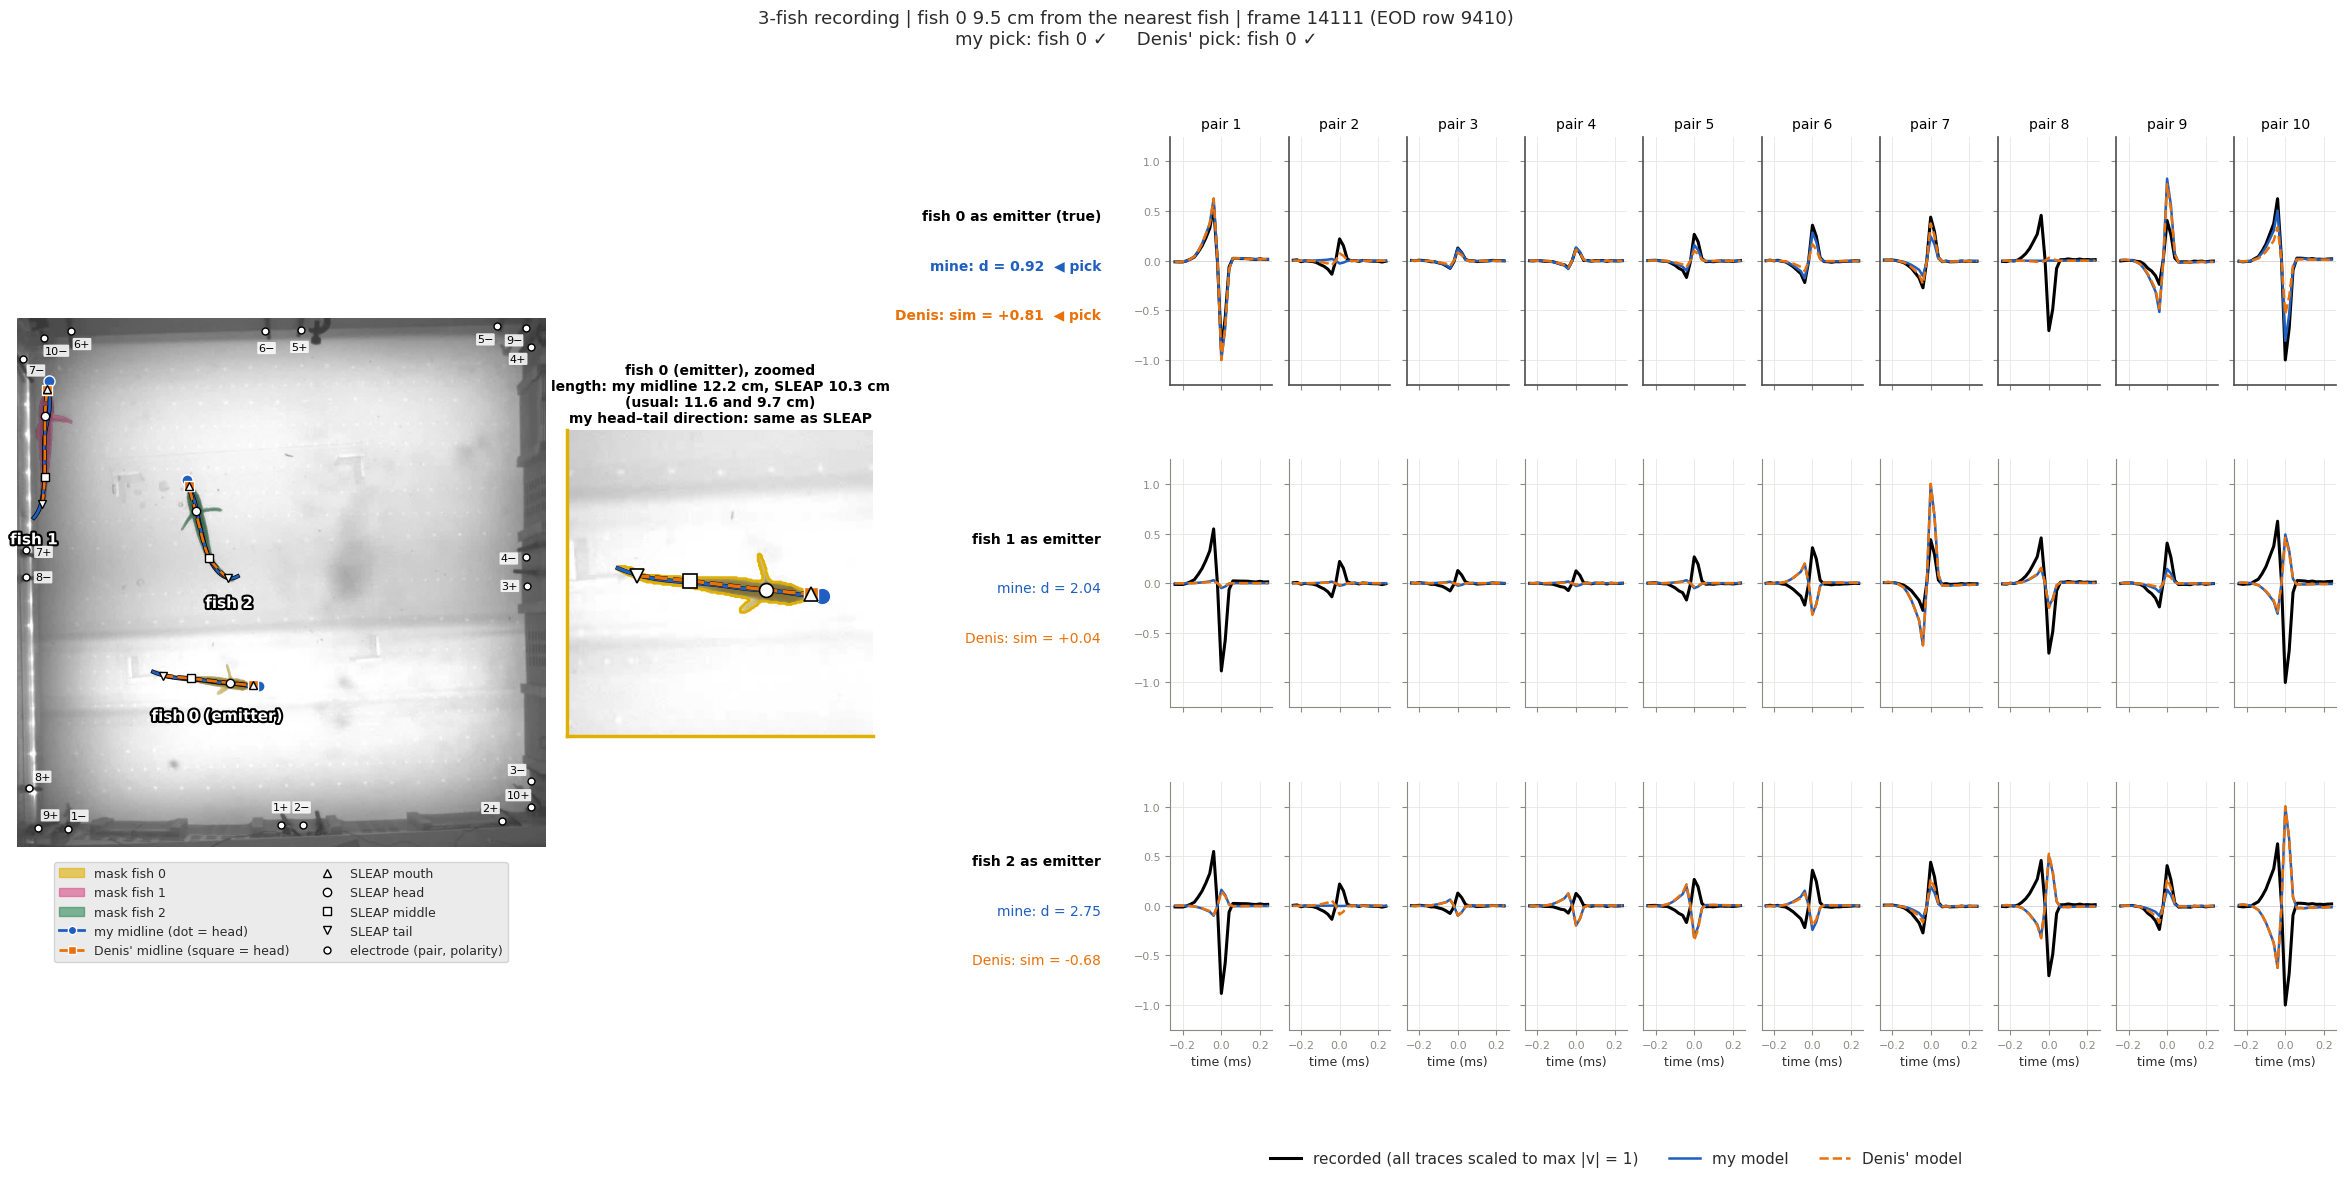

In [2]:
rows = c['df'].index[c['df'].Frame == FRAME]; i = int(rows[0]); a_ = c['assigned'].loc[i]; em = c['emitter']
print(f"frame {FRAME}: EOD row(s) {list(rows)} (using {i}) | in the better list: {a_['good frames']} | "
      f"fish {em} to nearest fish {a_.gap_cm:.1f} cm | my pick: fish {a_['fish | ' + ex.MINE]}, Denis: fish {a_['fish | ' + ex.DENIS]}")
ex.plot_example(c, i, f'3-fish recording | fish {em} {a_.gap_cm:.1f} cm from the nearest fish', f'{OUT}/frame{FRAME}_voltages.png')

## Field of each fish as the emitter (my model)

Colour: potential (red > 0, blue < 0; 0 = tank mean ≈ far field). Thin lines: equipotentials; **black: zero-potential line**; white:
field lines (E = −∇φ). Fish outlines, the emitting fish's midline (dot = head), electrodes with their potential. The solve is checked
against the cached voltages of `EOD_assignment_3_fish_conductivities.ipynb`.

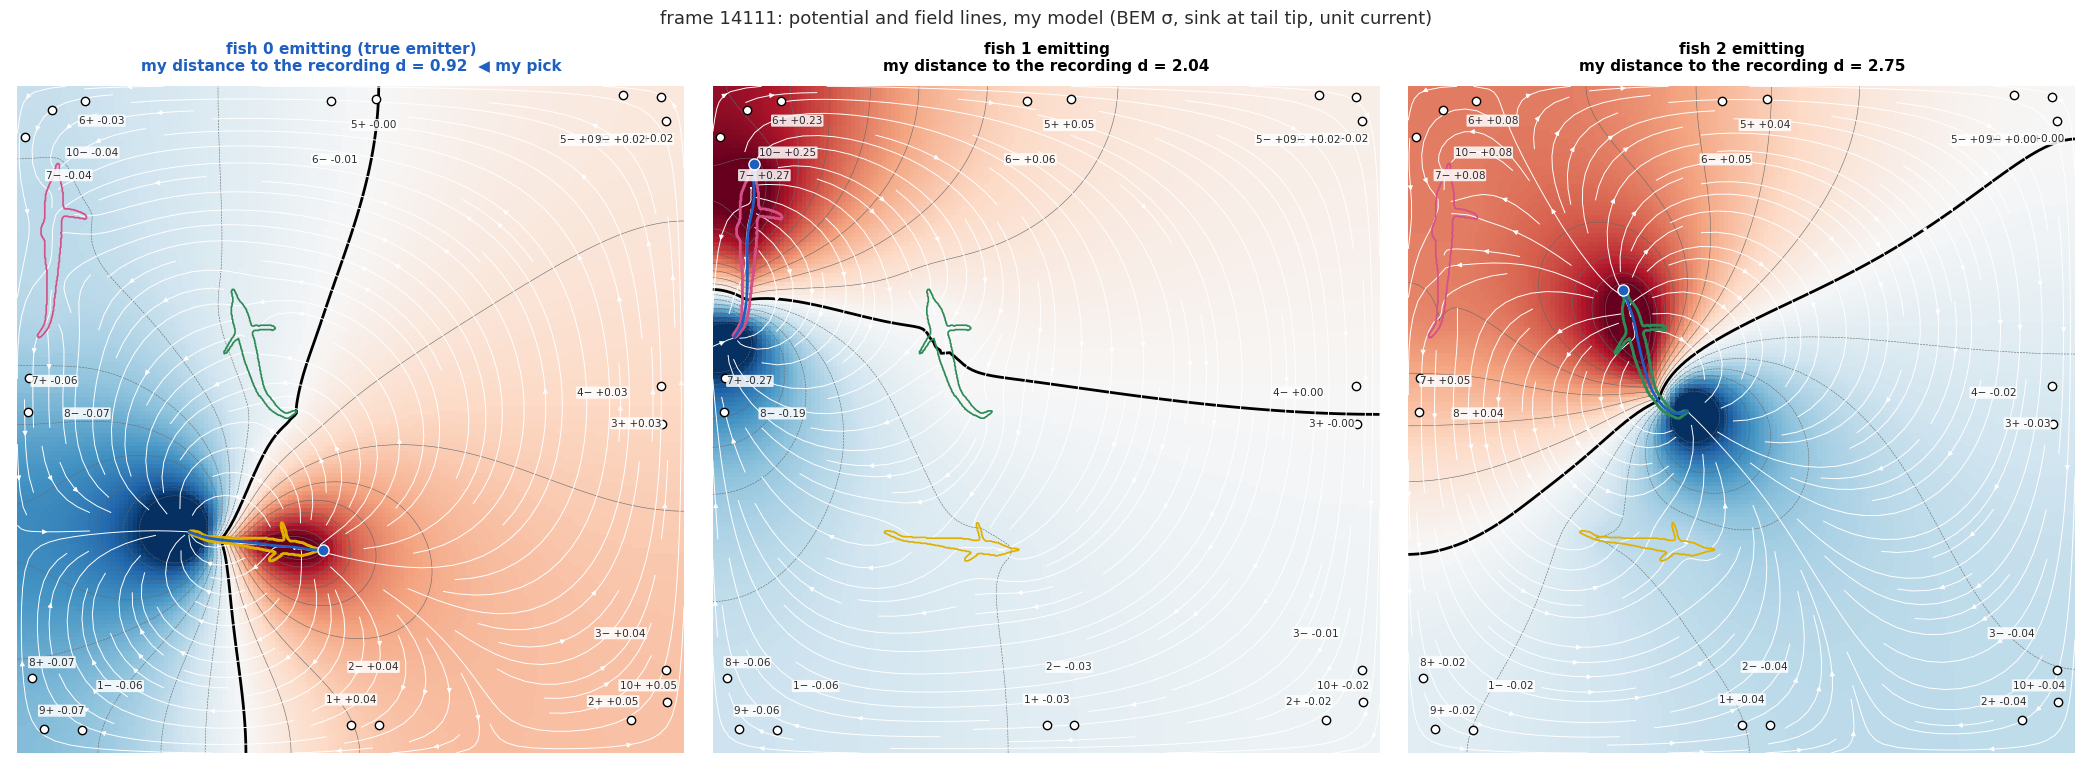

In [3]:
fm = ex.frame_masks(c, FRAME); mids = ex.fish_midlines(fm); P = c['P']
gw, gs, gi = gammas(0.0, **BEM)
phi = {}
for f in c['fish']:
    b = build_multipole_b(*multipole_sources(mids[f], I0=1.0, sink_frac=0.0), h, N)
    phi[f] = unflatten_to_grid(solve_potential(build_A_shell(occupancy_field(fm, N, skip=f), N, DELTA_H, gw, gs, gi), b), N).real

r, U = ex.my_patterns(c, i)                                         # cached: recorded pattern, model patterns (x -1, max |v| = 1)
for f in c['fish']:
    v = -pair_voltages(phi[f], c['pairs'], N); assert np.allclose(v / np.abs(v).max(), U[f], atol=1e-6)
d = np.linalg.norm(U - r, axis=1); pick = int(d.argmin())

g = np.linspace(0, P - 1, N)
fig, axs = plt.subplots(1, len(c['fish']), figsize=(7 * len(c['fish']), 7.6))
for a, f in zip(axs, c['fish']):
    p = phi[f]; v = np.percentile(np.abs(p), 99)
    a.imshow(p, extent=[0, P - 1, P - 1, 0], cmap='RdBu_r', vmin=-v, vmax=v)
    a.contour(g, g, p, levels=np.linspace(-v, v, 17), colors='0.4', linewidths=0.4)
    a.contour(g, g, p, levels=[0], colors='k', linewidths=2)
    Er, Ec = np.gradient(-p)                                        # E along rows, columns
    a.streamplot(g, g, Ec, Er, color='w', density=1.4, linewidth=0.7, arrowsize=0.7)
    for o in c['fish']:
        if fm[o].any(): a.contour(fm[o].astype(float), levels=[0.5], colors=[c['fish_color'][o]], linewidths=2 if o == f else 1.2)
    m = mids[f] * (P - 1); a.plot(m[:, 1], m[:, 0], color=ex.C_MINE, lw=2); a.plot(m[-1, 1], m[-1, 0], 'o', color=ex.C_MINE, mec='w', ms=8)
    for pid, pp, pm in c['pairs']:
        for pt, s in ((pp, '+'), (pm, '−')):
            y, x = pt * (P - 1); val = p[tuple(np.round(pt * (N - 1)).astype(int))]
            a.plot(x, y, 'o', color='w', mec='k', ms=6)
            off = np.array([P / 2 - x, P / 2 - y]); off = (35 if s == '+' else 80) * off / np.linalg.norm(off)   # + and − at two depths
            a.text(x + off[0], y + off[1], f'{pid}{s} {val:+.2f}', fontsize=7.5, ha='center', va='center',
                   bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.85))
    a.set(xlim=(-10, P + 10), ylim=(P + 10, -10)); a.set_axis_off()
    a.set_title(f"fish {f} emitting" + (' (true emitter)' if f == em else '') + f"\nmy distance to the recording d = {d[f]:.2f}" +
                ('  ◀ my pick' if f == pick else ''), fontsize=11, color=ex.C_MINE if f == pick else 'k')
plt.tight_layout(); fig.suptitle(f'frame {FRAME}: potential and field lines, my model (BEM σ, sink at tail tip, unit current)', fontsize=13, y=1.04); fig.savefig(f'{OUT}/frame{FRAME}_field.png', dpi=100, bbox_inches='tight'); plt.show()

## Orientation of the emitter relative to one electrode pair

Pair axis: from the − to the + electrode. Body axis: straight line tail tip → head of the emitter's mask midline. Tail axis: tail tip →
the midline point a fraction `TAIL_FRAC` of the body length from the tail tip (only the last bit of the body; three lengths shown).
Angles are as seen on the image (counter-clockwise > 0), from the pair axis to the fish axis; *acute* is the angle between the two
lines (0° = parallel, 90° = perpendicular), whatever the direction.

frame 14111, fish 0: midline 12.2 cm | pair 8: 8- -> 8+ 23.9 cm long, direction -89 deg on screen
  body (tail tip -> head)                          angle from pair axis   +81.6 deg | acute  81.6 deg | off perpendicular   8.4 deg
  tail, last 10% (1.2 cm; tail tip -> that point)  angle from pair axis   +70.2 deg | acute  70.2 deg | off perpendicular  19.8 deg
  tail, last 20% (2.4 cm; tail tip -> that point)  angle from pair axis   +73.8 deg | acute  73.8 deg | off perpendicular  16.2 deg
  tail, last 30% (3.6 cm; tail tip -> that point)  angle from pair axis   +76.8 deg | acute  76.8 deg | off perpendicular  13.2 deg


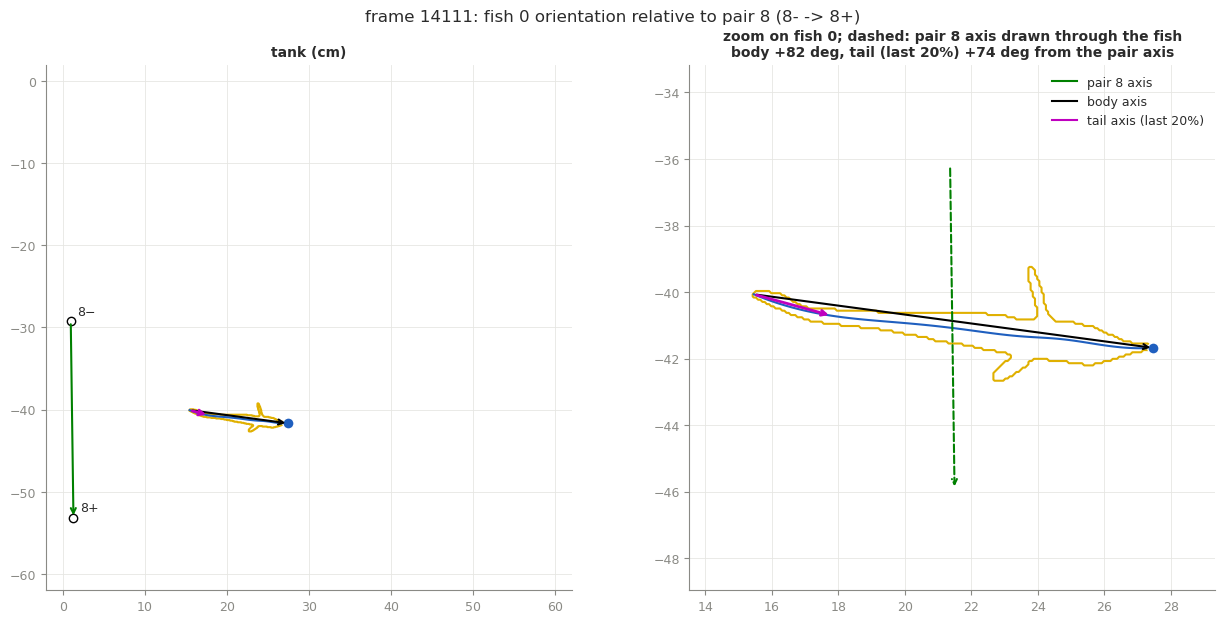

In [4]:
TAIL_FRACS = (0.1, 0.2, 0.3)                                        # last 10, 20, 30 % of the body
_, pp, pm = next(q for q in c['pairs'] if q[0] == PAIR)
xy = lambda pt: np.array([pt[1], -pt[0]]) * (P - 1) / ex.PX_PER_CM    # (row, col) / (P - 1) -> (x, y) in cm, y up as on screen
ang = lambda u, v: (np.degrees(np.arctan2(v[1], v[0]) - np.arctan2(u[1], u[0])) + 180) % 360 - 180
acute = lambda a: min(abs(a) % 180, 180 - abs(a) % 180)

m = np.array([xy(pt) for pt in mids[em]])                           # tail -> head
s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(m, axis=0), axis=1))]; L = s[-1]
along = lambda f: np.array([np.interp(f * L, s, m[:, 0]), np.interp(f * L, s, m[:, 1])])
u_pair = xy(pp) - xy(pm)
axes = {'body (tail tip -> head)': (m[0], m[-1])}
for tf in TAIL_FRACS: axes[f'tail, last {tf:.0%} ({tf * L:.1f} cm; tail tip -> that point)'] = (m[0], along(tf))
print(f"frame {FRAME}, fish {em}: midline {L:.1f} cm | pair {PAIR}: {PAIR}- -> {PAIR}+ {np.linalg.norm(u_pair):.1f} cm long, "
      f"direction {np.degrees(np.arctan2(u_pair[1], u_pair[0])):.0f} deg on screen")
for k, (a0, a1) in axes.items():
    a = ang(u_pair, a1 - a0)
    print(f"  {k:48s} angle from pair axis {a:+7.1f} deg | acute {acute(a):5.1f} deg | off perpendicular {90 - acute(a):5.1f} deg")

tf = 0.2                                                            # figure: tank (left) and zoom (right)
fig, axs = plt.subplots(1, 2, figsize=(13, 6.2))
for a in axs:
    a.contour(np.arange(P) / ex.PX_PER_CM, -np.arange(P) / ex.PX_PER_CM, fm[em].astype(float), levels=[0.5], colors=[c['fish_color'][em]])
    a.plot(m[:, 0], m[:, 1], color=ex.C_MINE, lw=1.5); a.plot(*m[-1], 'o', color=ex.C_MINE, mec='w', ms=8)
    a.annotate('', m[-1], m[0], arrowprops=dict(arrowstyle='->', color='k', lw=1.5))
    a.annotate('', along(tf), m[0], arrowprops=dict(arrowstyle='->', color='m', lw=2))
    a.annotate('', xy(pp), xy(pm), arrowprops=dict(arrowstyle='->', color='g', lw=1.5))
    for pt, sg in ((pp, '+'), (pm, '−')): a.plot(*xy(pt), 'o', color='w', mec='k'); a.text(*(xy(pt) + 0.8), f'{PAIR}{sg}', fontsize=9, clip_on=True)
    a.set_aspect('equal')
axs[0].set(xlim=(-2, P / ex.PX_PER_CM + 2), ylim=(-P / ex.PX_PER_CM - 2, 2), title=f'tank (cm)')
c0 = m.mean(0); axs[1].set(xlim=(c0[0] - 0.65 * L, c0[0] + 0.65 * L), ylim=(c0[1] - 0.65 * L, c0[1] + 0.65 * L))
for k, col in ((f'pair {PAIR} axis', 'g'), ('body axis', 'k'), (f'tail axis (last {tf:.0%})', 'm')):   # pair axis also through the fish
    if col == 'g': axs[1].annotate('', c0 + 0.4 * L * u_pair / np.linalg.norm(u_pair), c0 - 0.4 * L * u_pair / np.linalg.norm(u_pair),
                                   arrowprops=dict(arrowstyle='->', color='g', lw=1.5, ls='--'))
    axs[1].plot([], [], color=col, label=k)
axs[1].legend(loc='upper right', fontsize=9)
axs[1].set_title(f"zoom on fish {em}; dashed: pair {PAIR} axis drawn through the fish\n"
                 f"body {ang(u_pair, m[-1] - m[0]):+.0f} deg, tail (last {tf:.0%}) {ang(u_pair, along(tf) - m[0]):+.0f} deg from the pair axis",
                 fontsize=10)
fig.suptitle(f'frame {FRAME}: fish {em} orientation relative to pair {PAIR} ({PAIR}- -> {PAIR}+)', fontsize=12)
plt.tight_layout(); fig.savefig(f'{OUT}/frame{FRAME}_orientation_pair{PAIR}.png', dpi=100, bbox_inches='tight'); plt.show()

## Neighbouring video frames (timing check)

The same recorded EOD compared with my model built from the masks of nearby video frames (`OFFSETS`, at the recording's fps):
every fish's mask and the emitter's midline from that frame, the rest as above. If a frame other than the EOD's own fits much
better, the fish was moving fast and the EOD ↔ video-frame timing matters.

frame 14111 (EOD row 9410), fish 0, 50 fps; recorded pattern of this EOD vs the model from nearby frames
  offset -25 ( -500 ms): heading   -7.3 deg, d = 0.96
  offset -24 ( -480 ms): heading   -7.3 deg, d = 0.97
  offset -23 ( -460 ms): heading   -8.3 deg, d = 0.92
  offset -22 ( -440 ms): heading   -8.5 deg, d = 0.89
  offset -21 ( -420 ms): heading  -10.7 deg, d = 0.75
  offset -20 ( -400 ms): heading  -11.9 deg, d = 0.69
  offset -19 ( -380 ms): heading  -14.2 deg, d = 0.53
  offset -18 ( -360 ms): heading  -15.8 deg, d = 0.46
  offset -17 ( -340 ms): heading  -18.4 deg, d = 0.41  <- best
  offset -16 ( -320 ms): heading  -20.6 deg, d = 0.44
  offset -15 ( -300 ms): heading  -22.2 deg, d = 0.49
  offset -14 ( -280 ms): heading  -23.5 deg, d = 0.57
  offset -13 ( -260 ms): heading  -24.4 deg, d = 0.61
  offset -12 ( -240 ms): heading  -23.4 deg, d = 0.59
  offset -11 ( -220 ms): heading  -23.3 deg, d = 0.62
  offset -10 ( -200 ms): heading  -23.3 deg, d = 0.61
  offset  -9 ( -180 ms

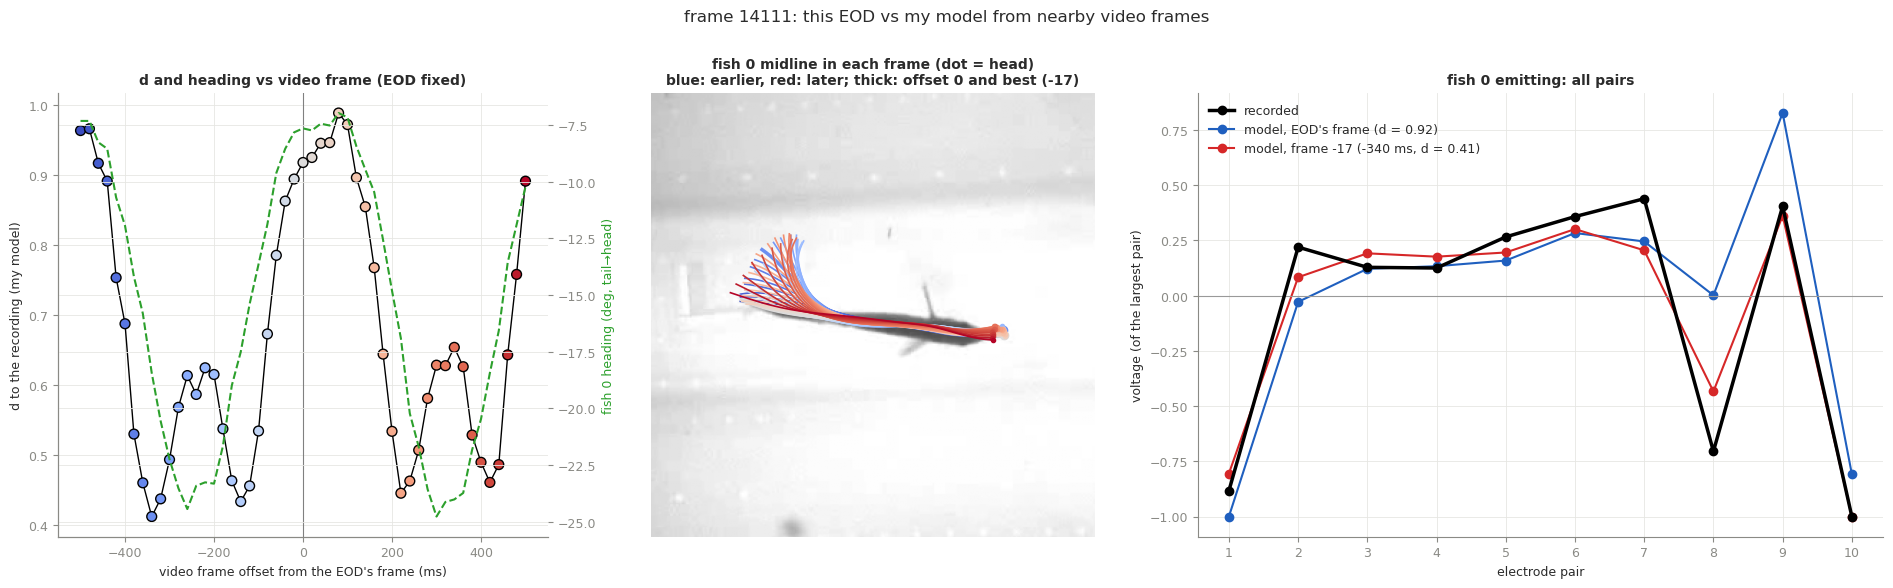

In [5]:
OFFSETS = range(-25, 26)
A_of = lambda fms: build_A_shell(occupancy_field(fms, N, skip=em), N, DELTA_H, gw, gs, gi)
def u_from(fms, mid):
    v = -pair_voltages(unflatten_to_grid(solve_potential(A_of(fms), build_multipole_b(*multipole_sources(mid, I0=1.0, sink_frac=0.0), h, N)), N).real, c['pairs'], N)
    return v / np.abs(v).max()
nbr = {}
for k in OFFSETS:
    f2 = ex.frame_masks(c, FRAME + k); m2 = ex.fish_midlines(f2)
    if m2[em] is None: continue
    hd = (m2[em][-1] - m2[em][0]) * [-1, 1]; u2 = u_from(f2, m2[em])
    nbr[k] = dict(mid=m2[em], mask=f2[em], u=u2, d=np.linalg.norm(u2 - r), heading=np.degrees(np.arctan2(hd[0], hd[1])))
assert np.isclose(nbr[0]['d'], d[em], atol=1e-6)                    # offset 0 = the model above
kb = min(nbr, key=lambda k: nbr[k]['d'])
print(f"frame {FRAME} (EOD row {i}), fish {em}, {c['fps']:g} fps; recorded pattern of this EOD vs the model from nearby frames")
for k, q in nbr.items():
    print(f"  offset {k:+3d} ({1000 * k / c['fps']:+5.0f} ms): heading {q['heading']:+6.1f} deg, d = {q['d']:.2f}" + ('  <- best' if k == kb else ''))
print(f"{'':22s}" + ' '.join(f'{"p" + str(q):>6s}' for q in c['pair_ids']))
for lab, u in (('recorded', r), ('offset 0', nbr[0]['u']), (f'offset {kb:+d} (best)', nbr[kb]['u'])): print(f"{lab:22s}" + ' '.join(f'{x:+6.2f}' for x in u))

fig, axs = plt.subplots(1, 3, figsize=(19, 5.6), gridspec_kw=dict(width_ratios=[1, 1, 1.4]))
ks = list(nbr); cm = plt.cm.coolwarm((np.array(ks) - min(ks)) / (max(ks) - min(ks)))
a = axs[0]
a.plot([1000 * k / c['fps'] for k in ks], [nbr[k]['d'] for k in ks], 'k-', lw=1)
a.scatter([1000 * k / c['fps'] for k in ks], [nbr[k]['d'] for k in ks], c=cm, s=50, zorder=3, edgecolor='k')
a2 = a.twinx(); a2.plot([1000 * k / c['fps'] for k in ks], [nbr[k]['heading'] for k in ks], '--', color='tab:green'); a2.set_ylabel(f'fish {em} heading (deg, tail→head)', color='tab:green')
a.axvline(0, color='0.5', lw=0.8); a.set(xlabel='video frame offset from the EOD\'s frame (ms)', ylabel='d to the recording (my model)', title=f'd and heading vs video frame (EOD fixed)')
a = axs[1]; mm_all = np.concatenate([nbr[k]['mid'] for k in ks]) * (P - 1); cen = mm_all.mean(0); half = 0.6 * np.ptp(mm_all, axis=0).max() + 40
a.imshow(ex.video_frame(c, FRAME), cmap='gray', extent=[0, P - 1, P - 1, 0])
for k, col in zip(ks, cm):
    m_ = nbr[k]['mid'] * (P - 1); a.plot(m_[:, 1], m_[:, 0], color=col, lw=2.5 if k in (0, kb) else 1.2); a.plot(m_[-1, 1], m_[-1, 0], 'o', color=col, ms=6 if k in (0, kb) else 3)
a.set(xlim=(cen[1] - half, cen[1] + half), ylim=(cen[0] + half, cen[0] - half), title=f'fish {em} midline in each frame (dot = head)\nblue: earlier, red: later; thick: offset 0 and best ({kb:+d})')
a.set_axis_off()
a = axs[2]; x = np.arange(len(c['pair_ids']))
a.plot(x, r, 'k-o', lw=2.5, label='recorded', zorder=5)
a.plot(x, nbr[0]['u'], 'o-', color=ex.C_MINE, label=f"model, EOD's frame (d = {nbr[0]['d']:.2f})")
a.plot(x, nbr[kb]['u'], 'o-', color='tab:red', label=f"model, frame {kb:+d} ({1000 * kb / c['fps']:+.0f} ms, d = {nbr[kb]['d']:.2f})")
a.axhline(0, color='0.6', lw=0.8); a.set(xticks=x, xticklabels=c['pair_ids'], xlabel='electrode pair', ylabel='voltage (of the largest pair)', title=f'fish {em} emitting: all pairs')
a.legend(fontsize=9)
fig.suptitle(f'frame {FRAME}: this EOD vs my model from nearby video frames', fontsize=12, y=1.04)
plt.tight_layout(); fig.savefig(f'{OUT}/frame{FRAME}_neighbour_frames.png', dpi=100, bbox_inches='tight'); plt.show()

## Recorded EOD vs the fish `THEN` frames away (positions then and now)

The recorded traces of this EOD against my model built from the masks and midlines of frame `FRAME + THEN`, one row per candidate
emitter (as in the voltages figure above); the fish 0 row also shows the model from the EOD's own frame. Left: the tank at both
frames and a zoom with fish 0 then and now. (Denis' predictions exist only for the EOD's own frame, so they are not shown.)

EOD row 9410: frame 14111 (now) vs frame 14094 (-340 ms, then)
  fish 0 as emitter: d now 0.92, d then 0.41
  fish 1 as emitter: d now 2.04, d then 2.13
  fish 2 as emitter: d now 2.75, d then 2.73
  pick now: fish 0, pick then: fish 0
  fish 0: mask centre moved 0.3 cm, head moved 0.2 cm
  fish 1: mask centre moved 1.4 cm, head moved 1.7 cm
  fish 2: mask centre moved 1.0 cm, head moved 1.1 cm


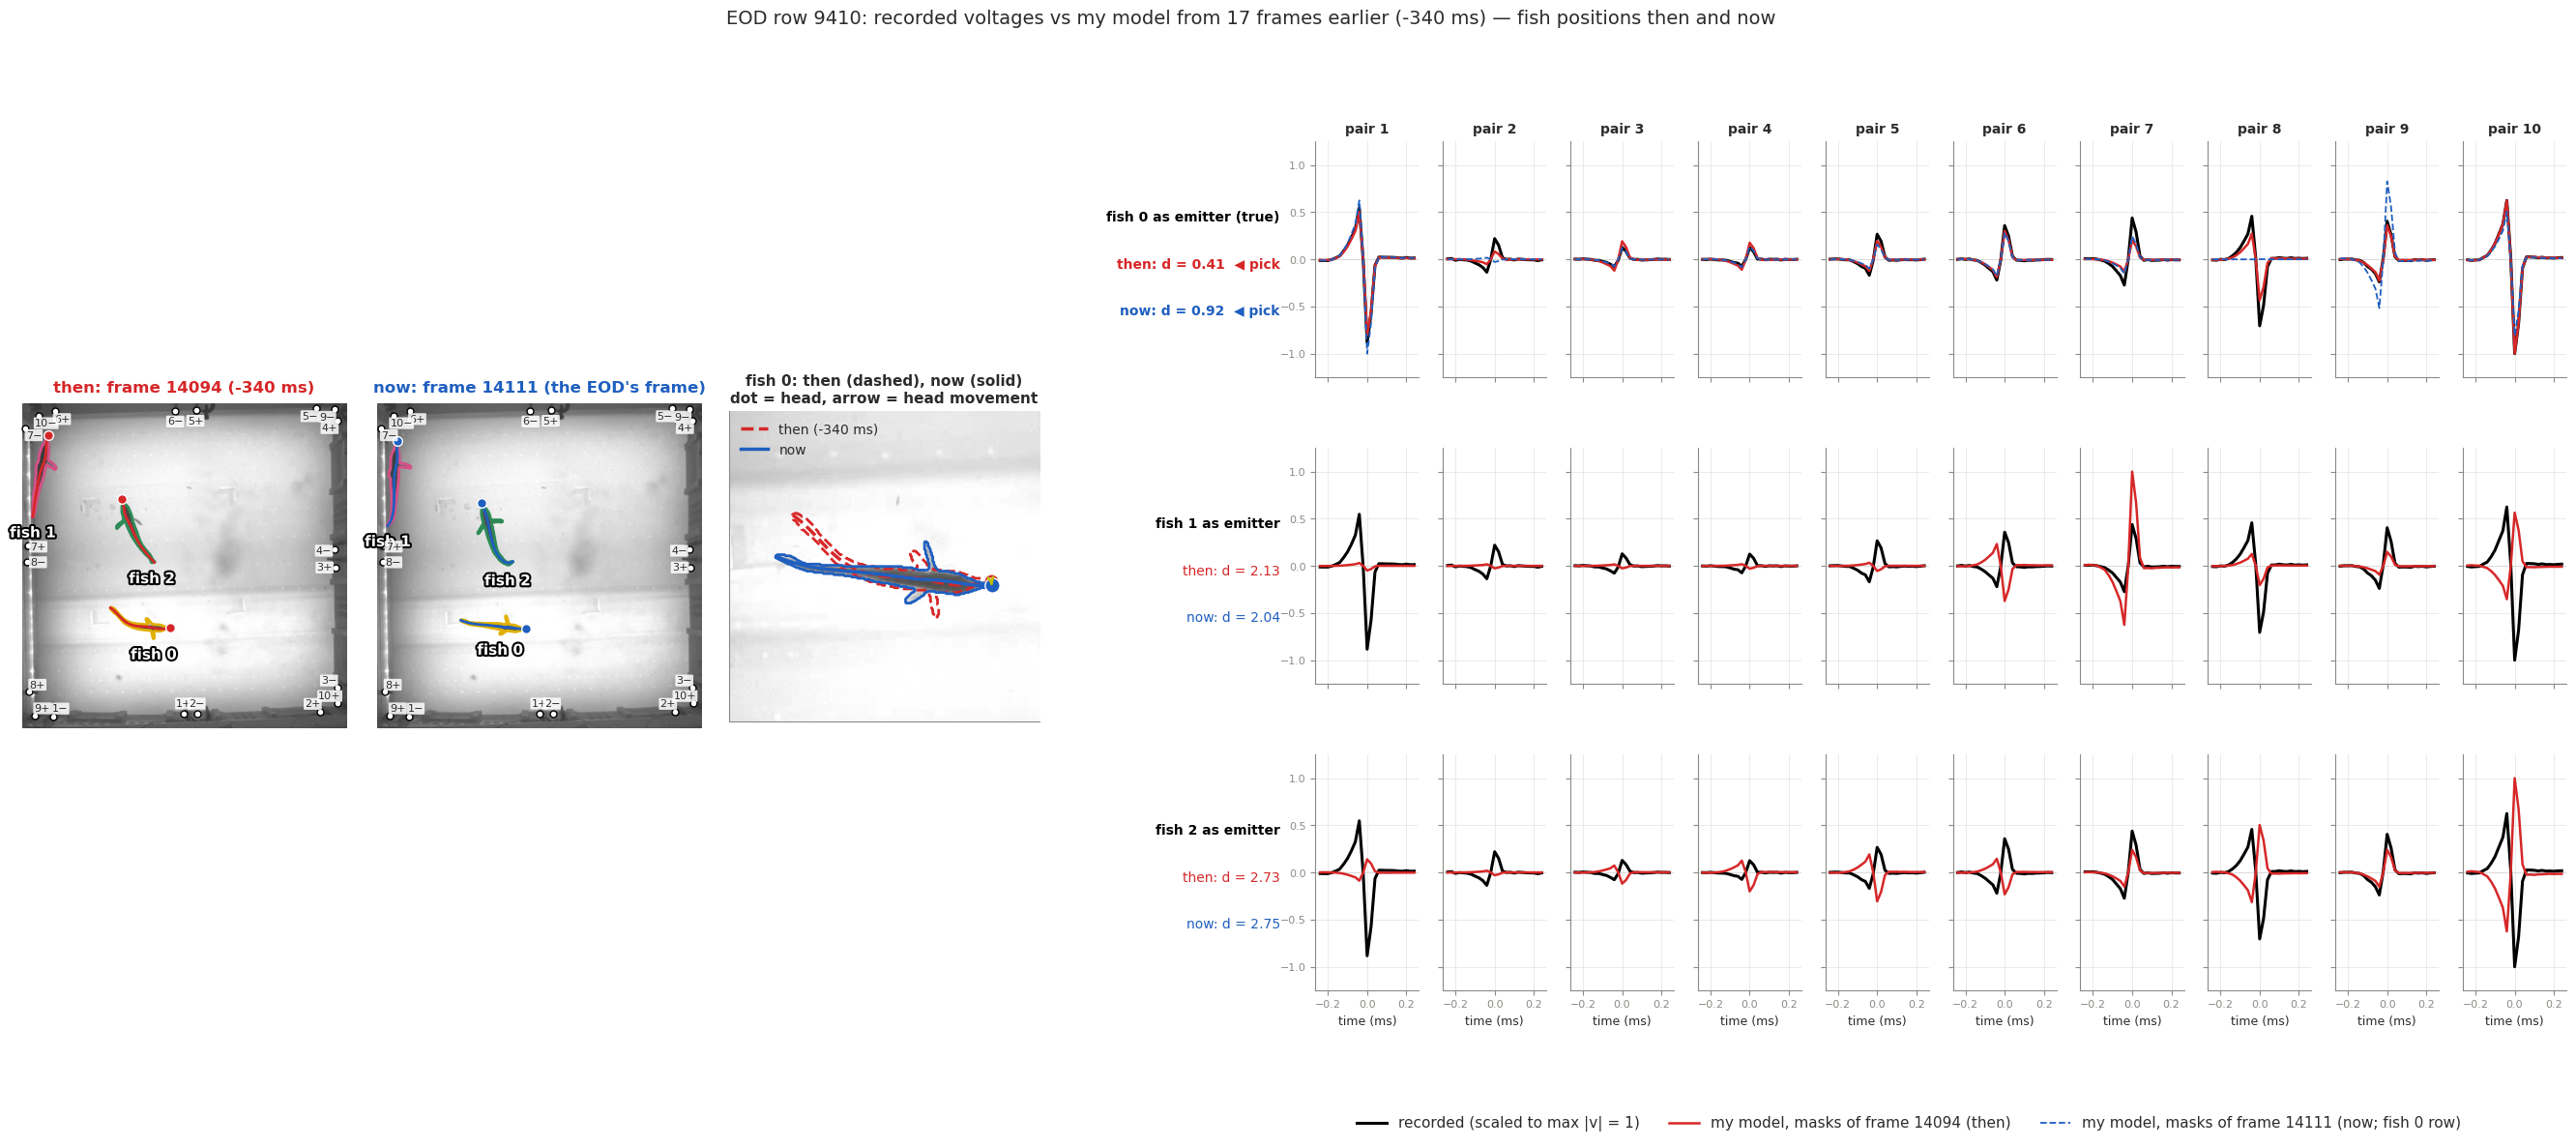

In [6]:
THEN = kb                                                           # video frames from the EOD's frame (default: best offset above)
from matplotlib.lines import Line2D
from eod_assign import peak_pattern, rank1_pattern
k_now, k_then = FRAME, FRAME + THEN
fm_then = ex.frame_masks(c, k_then); mids_then = ex.fish_midlines(fm_then)
def u_for(fms, f, mid):                                              # pattern (x -1, max |v| = 1), fish f emitting, masks fms
    v = -pair_voltages(unflatten_to_grid(solve_potential(build_A_shell(occupancy_field(fms, N, skip=f), N, DELTA_H, gw, gs, gi),
                       build_multipole_b(*multipole_sources(mid, I0=1.0, sink_frac=0.0), h, N)), N).real, c['pairs'], N)
    return v / np.abs(v).max()
U_then = np.array([u_for(fm_then, f, mids_then[f]) for f in c['fish']])
d_then = np.linalg.norm(U_then - r, axis=1)
V = ex.recorded_pair_traces(c, i); rr, ts = peak_pattern(V); rmax = np.abs(rr).max()
w = rank1_pattern(V)[1]; w = w / w[ts]; t_ms = (np.arange(V.shape[1]) - V.shape[1] // 2) / ex.FS * 1e3
print(f"EOD row {i}: frame {k_now} (now) vs frame {k_then} ({1000 * THEN / c['fps']:+.0f} ms, then)")
for f in c['fish']: print(f"  fish {f} as emitter: d now {d[f]:.2f}, d then {d_then[f]:.2f}")
print(f"  pick now: fish {int(np.argmin(d))}, pick then: fish {int(np.argmin(d_then))}")
for f in c['fish']:
    if mids[f] is not None and mids_then[f] is not None:
        hn, ht_ = mids[f][-1] * (P - 1), mids_then[f][-1] * (P - 1); cn, ct = fm[f].nonzero(), fm_then[f].nonzero()
        mv = np.hypot(np.mean(cn[0]) - np.mean(ct[0]), np.mean(cn[1]) - np.mean(ct[1])) / ex.PX_PER_CM
        print(f"  fish {f}: mask centre moved {mv:.1f} cm, head moved {np.linalg.norm(hn - ht_) / ex.PX_PER_CM:.1f} cm")

nf = len(c['fish']); C_THEN, C_NOW = 'tab:red', ex.C_MINE
fig = plt.figure(figsize=(34, 3.0 * nf + 2.4))
gsp = fig.add_gridspec(nf, 14, width_ratios=[3.2, 3.2, 3.0, 2.2] + [1] * 10, wspace=0.15, hspace=0.3)
for col, (k_, fms, mds, lab) in enumerate(((k_then, fm_then, mids_then, f'then: frame {k_then} ({1000 * THEN / c["fps"]:+.0f} ms)'),
                                          (k_now, fm, mids, f"now: frame {k_now} (the EOD's frame)"))):
    a = fig.add_subplot(gsp[:, col]); a.imshow(ex.video_frame(c, k_), cmap='gray')
    for f in c['fish']:
        if fms[f].any(): a.contour(fms[f].astype(float), levels=[0.5], colors=[c['fish_color'][f]], linewidths=2)
        if mds[f] is not None:
            m_ = mds[f] * (P - 1); a.plot(m_[:, 1], m_[:, 0], color=C_THEN if col == 0 else C_NOW, lw=2); a.plot(m_[-1, 1], m_[-1, 0], 'o', color=C_THEN if col == 0 else C_NOW, mec='w', ms=7)
            yx = np.argwhere(fms[f]); y_, x_ = yx[np.argmax(yx[:, 0])]
            a.text(x_, min(y_ + 25, P - 5), f'fish {f}', color='w', fontsize=11, fontweight='bold', ha='center', va='top', path_effects=ex.OUTLINE)
    for pid, pp_, pm_ in c['pairs']:
        for pt, sg in ((pp_, '+'), (pm_, '−')):
            y_, x_ = pt * (P - 1); a.plot(x_, y_, 'o', color='w', mec='k', ms=5)
            off = np.array([P / 2 - x_, P / 2 - y_]); off = 30 * off / np.linalg.norm(off)
            a.text(x_ + off[0], y_ + off[1], f'{pid}{sg}', fontsize=8, ha='center', va='center', bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.85))
    a.set(xlim=(-10, P + 10), ylim=(P + 10, -10)); a.set_axis_off(); a.set_title(lab, fontsize=12, color=C_THEN if col == 0 else C_NOW)
z = fig.add_subplot(gsp[:, 2]); z.imshow(ex.video_frame(c, k_now), cmap='gray')     # zoom: fish em then and now
both = np.argwhere(fm[em] | fm_then[em]); (y0, x0), (y1, x1) = both.min(0), both.max(0); hz = max(y1 - y0, x1 - x0) / 2 + 40
cy, cx = (y0 + y1) / 2, (x0 + x1) / 2
for fms, mds, col, ls, lab in ((fm_then, mids_then, C_THEN, '--', f'then ({1000 * THEN / c["fps"]:+.0f} ms)'), (fm, mids, C_NOW, '-', 'now')):
    z.contour(fms[em].astype(float), levels=[0.5], colors=[col], linewidths=2, linestyles=ls)
    m_ = mds[em] * (P - 1); z.plot(m_[:, 1], m_[:, 0], color=col, lw=2.5, ls=ls, label=lab); z.plot(m_[-1, 1], m_[-1, 0], 'o', color=col, mec='w', ms=11)
hdn = mids[em][-1] * (P - 1); hdt = mids_then[em][-1] * (P - 1)
z.annotate('', hdn[::-1], hdt[::-1], arrowprops=dict(arrowstyle='->', color='y', lw=2))
z.set(xlim=(cx - hz, cx + hz), ylim=(cy + hz, cy - hz)); z.set_xticks([]); z.set_yticks([])
z.legend(loc='upper left', fontsize=10); z.set_title(f'fish {em}: then (dashed), now (solid)\ndot = head, arrow = head movement', fontsize=11)
for row, f in enumerate(c['fish']):
    la = fig.add_subplot(gsp[row, 3]); la.set_axis_off()
    txt = [(f"fish {f} as emitter" + (' (true)' if f == em else ''), 'k', 'bold'),
           (f"then: d = {d_then[f]:.2f}" + ('  ◀ pick' if f == np.argmin(d_then) else ''), C_THEN, 'bold' if f == np.argmin(d_then) else 'normal'),
           (f"now: d = {d[f]:.2f}" + ('  ◀ pick' if f == np.argmin(d) else ''), C_NOW, 'bold' if f == np.argmin(d) else 'normal')]
    for j, (s_, col, fw) in enumerate(txt): la.text(0.95, 0.68 - 0.2 * j, s_, color=col, fontweight=fw, fontsize=10, ha='right', va='center', transform=la.transAxes)
    for kk, pid in enumerate(c['pair_ids']):
        ax = fig.add_subplot(gsp[row, 4 + kk]); ax.axhline(0, color='0.85', lw=0.6)
        ax.plot(t_ms, V[kk] / rmax, color='k', lw=2.2)
        ax.plot(t_ms, U_then[f, kk] * w, color=C_THEN, lw=1.8)
        if f == em: ax.plot(t_ms, U[f, kk] * w, color=C_NOW, lw=1.3, ls='--')
        ax.set_ylim(-1.25, 1.25); ax.set_xticks([-0.2, 0, 0.2]); ax.tick_params(labelsize=8)
        if row == 0: ax.set_title(f'pair {pid}', fontsize=10)
        if kk: ax.set_yticklabels([])
        if row < nf - 1: ax.set_xticklabels([])
        else: ax.set_xlabel('time (ms)', fontsize=9)
fig.legend(handles=[Line2D([], [], color='k', lw=2.2, label='recorded (scaled to max |v| = 1)'),
                    Line2D([], [], color=C_THEN, lw=1.8, label=f'my model, masks of frame {k_then} (then)'),
                    Line2D([], [], color=C_NOW, lw=1.3, ls='--', label=f"my model, masks of frame {k_now} (now; fish {em} row)")],
           loc='lower center', bbox_to_anchor=(0.7, -0.03), ncol=3, fontsize=11, frameon=False)
fig.suptitle(f'EOD row {i}: recorded voltages vs my model from {abs(THEN)} frames {"earlier" if THEN < 0 else "later"} ({1000 * THEN / c["fps"]:+.0f} ms) — fish positions then and now', fontsize=14, y=1.0)
fig.savefig(f'{OUT}/frame{FRAME}_then{THEN:+d}_voltages.png', dpi=100, bbox_inches='tight'); plt.show()

### Field of each fish as the emitter, `THEN` frames away

As the field figure above, with every fish's mask and midline from frame `FRAME + THEN`; d is to this EOD's recording.

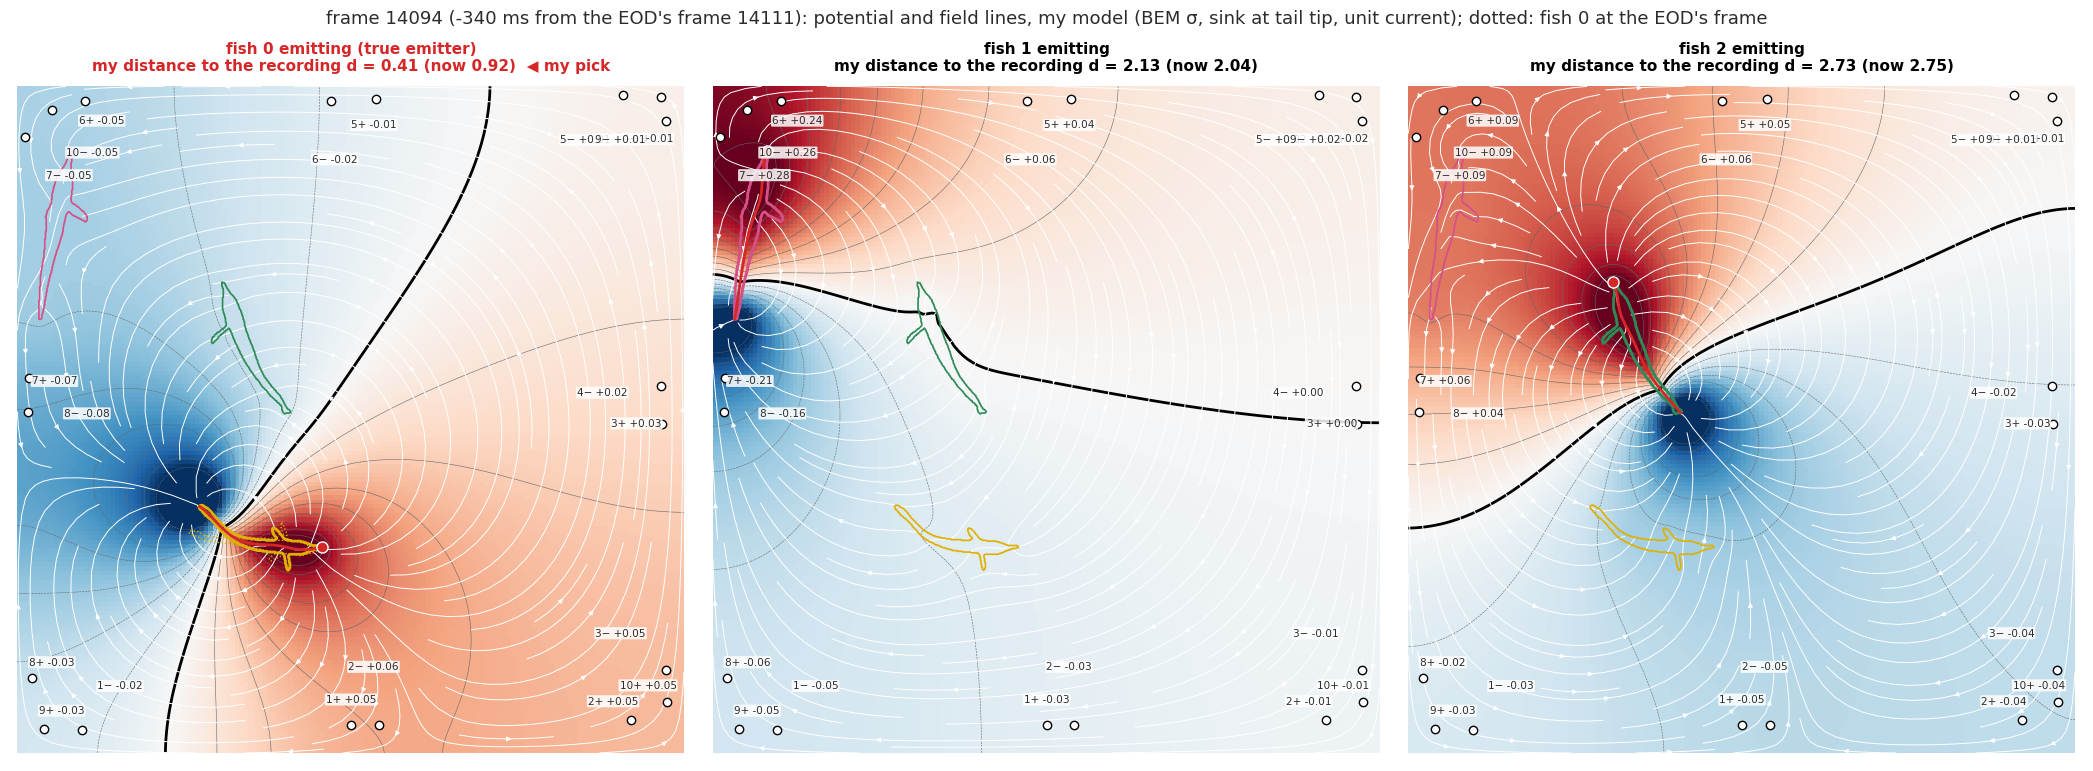

In [7]:
phi_then = {}
for f in c['fish']:
    b = build_multipole_b(*multipole_sources(mids_then[f], I0=1.0, sink_frac=0.0), h, N)
    phi_then[f] = unflatten_to_grid(solve_potential(build_A_shell(occupancy_field(fm_then, N, skip=f), N, DELTA_H, gw, gs, gi), b), N).real
    v = -pair_voltages(phi_then[f], c['pairs'], N); assert np.allclose(v / np.abs(v).max(), U_then[f], atol=1e-6)
pick_then = int(d_then.argmin())
fig, axs = plt.subplots(1, len(c['fish']), figsize=(7 * len(c['fish']), 7.6))
for a, f in zip(axs, c['fish']):
    p = phi_then[f]; v = np.percentile(np.abs(p), 99)
    a.imshow(p, extent=[0, P - 1, P - 1, 0], cmap='RdBu_r', vmin=-v, vmax=v)
    a.contour(g, g, p, levels=np.linspace(-v, v, 17), colors='0.4', linewidths=0.4)
    a.contour(g, g, p, levels=[0], colors='k', linewidths=2)
    Er, Ec = np.gradient(-p)
    a.streamplot(g, g, Ec, Er, color='w', density=1.4, linewidth=0.7, arrowsize=0.7)
    for o in c['fish']:
        if fm_then[o].any(): a.contour(fm_then[o].astype(float), levels=[0.5], colors=[c['fish_color'][o]], linewidths=2 if o == f else 1.2)
    if f == em: a.contour(fm[em].astype(float), levels=[0.5], colors=[c['fish_color'][em]], linewidths=1, linestyles=':')   # fish em now
    m = mids_then[f] * (P - 1); a.plot(m[:, 1], m[:, 0], color='tab:red', lw=2); a.plot(m[-1, 1], m[-1, 0], 'o', color='tab:red', mec='w', ms=8)
    for pid, pp, pm in c['pairs']:
        for pt, s in ((pp, '+'), (pm, '−')):
            y, x = pt * (P - 1); val = p[tuple(np.round(pt * (N - 1)).astype(int))]
            a.plot(x, y, 'o', color='w', mec='k', ms=6)
            off = np.array([P / 2 - x, P / 2 - y]); off = (35 if s == '+' else 80) * off / np.linalg.norm(off)
            a.text(x + off[0], y + off[1], f'{pid}{s} {val:+.2f}', fontsize=7.5, ha='center', va='center',
                   bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.85))
    a.set(xlim=(-10, P + 10), ylim=(P + 10, -10)); a.set_axis_off()
    a.set_title(f"fish {f} emitting" + (' (true emitter)' if f == em else '') + f"\nmy distance to the recording d = {d_then[f]:.2f} (now {d[f]:.2f})" +
                ('  ◀ my pick' if f == pick_then else ''), fontsize=11, color='tab:red' if f == pick_then else 'k')
plt.tight_layout()
fig.suptitle(f'frame {k_then} ({1000 * THEN / c["fps"]:+.0f} ms from the EOD\'s frame {FRAME}): potential and field lines, my model '
             f'(BEM σ, sink at tail tip, unit current); dotted: fish {em} at the EOD\'s frame', fontsize=13, y=1.04)
fig.savefig(f'{OUT}/frame{FRAME}_then{THEN:+d}_field.png', dpi=100, bbox_inches='tight'); plt.show()

## Notes

**Frame 14111** (EOD row 9410; both right; fish 0 9.5 cm from the nearest fish, mask 12.2 cm, head–tail as SLEAP):
- fish 0's field is a dipole along its body (sink at the tail, positive towards the head), with the zero-potential line crossing it
  near mid-body; my model fits the recording best for fish 0 (d = 0.92 vs 2.04 and 2.75); Denis agrees (similarity 0.81).
- the largest misfit is **pair 8**: recorded −0.70, model ≈ 0. Both of its electrodes (8+ and 8−, on the left wall) sit in fish 0's
  negative lobe at the same potential (−0.07), so the model gives no voltage; Denis' model also gives ≈ 0 there.
- smaller misfits: pair 2 (recorded −0.1 then +0.2; model ≈ 0) and pair 5 (recorded +0.25, model +0.1).

- **tests on pair 8** (all in `EOD_debug_frames_3fish_frame14111.ipynb`, figures `debug_frames/frame14111_*.png`):
  - orientation: body 8° off perpendicular to the 8−→8+ axis, tail (last 10–30 %) 13–20° off.
  - rotating the whole midline clockwise: pair 8 +0.00 → −0.42 at 20° (d 0.92 → 0.41), −0.56 at 30° (d rises again to 0.51).
  - 1–15 sink points at the tail (currents summing to 0): no change (pair 8 ≤ +0.05).
  - emitter as a body (thesis: skin by zone, interior profile, electric organ in the tail): pair 8 −0.03 at N = 300 (d 0.93 → 0.87).
    Scaling its skin/interior: best only at unphysical values (interior ≈ water): pair 8 −0.30, d 0.51.
  - other fish's interior 0.01–10⁴ × water, skin × 0.001–1000: d 0.88–0.93, pair 8 −0.08 to +0.01; only pair 7 moves (fish 1 sits
    between 7− and 7+; it shorts them when conductive).
  - not explained: only turning the current axis moves pair 8 much, and nothing reaches −0.70. Next suspect: pair 8's electrode
    positions / wiring (check across all good-frame EODs).

**Frame 34056** (EOD row 19745; only mine right, Denis picked fish 2; fish 0 27 cm from the others, mask 11.8 cm, head–tail as SLEAP):
- with the EOD's own frame the fit is poor for every fish (mine d = 1.76 / 2.42 / 1.86; Denis' similarity 0.33 / 0.03 / 0.35):
  recorded pair 1 ≈ 0 (model −1.00), pair 7 −0.08 (model +0.33), pair 8 −1.00 (model −0.37), pair 9 −0.81 (model +0.36, opposite sign).
- fish 0 is turning fast here: heading −66° at −120 ms, −32° at the EOD's frame, +25° at +240 ms (50 fps). The model from the
  masks of 4–8 frames earlier fits the recording well: d = 0.30 at −6 frames (−120 ms), 0.34 at −4, vs 1.76 at 0; pairs 1, 7, 8, 9 all
  match there. Rotating the EOD-frame midline 60° clockwise gives d = 0.34 too.
- so this EOD looks like a timing problem (the recorded EOD matches the fish's pose ~100 ms before the video frame it is assigned
  to), not a field-model problem. Frame 14111 (fish turning slowly in place) also fits better at ±6–12 frames (d 0.46 vs 0.92), with
  no clear direction there.
- to check: whether a fixed EOD ↔ video offset improves the fit across all good-frame EODs (how `Frame` is assigned to each EOD).

**Frame 14111, nearby frames** (offsets −25…+25, figures `debug_frames/frame14111_neighbour_frames.png`, `frame14111_then-17_*.png`):
- fish 0's head stays put (moves 0.2 cm); its tail swings slowly up and down (tail→head heading between −7° and −25°, ~0.6 s period).
  The EOD's frame is at the straight end of that swing (−7.6°, d = 0.92).
- d follows the tail, not time: it is low (0.41–0.46) whenever the heading is ≈ −16 to −20°, i.e. tail bent up towards 8− —
  at offsets −17 (best, d = 0.41, pair 8 −0.43), −7 (0.43), +11 (0.44), +21 (0.46). Same effect as rotating the midline 10–15°.
- the nearest good one, −6/−7 frames (−120/−140 ms; d 0.46/0.43), is the same offset as frame 34056's best (−6, d 0.30).
